DATA OVERVIEW
Shape: (5000, 7)

First 5 rows:
   temperature   humidity   rainfall   soil_ph  plant_age  disease_score  \
0    27.483571  53.643605  19.375501  9.235960         44      35.157232   
1    24.308678  53.198788   5.436041  7.068770         76      33.021848   
2    28.238443  33.065352   3.725809  5.870114        104      24.202767   
3    32.615149  55.048647   4.951032  6.847916        115      36.434388   
4    23.829233  70.992436  43.717791  8.280639         16      45.360639   

   target  
0       0  
1       0  
2       0  
3       0  
4       1  

Data Types and Missing Values:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperature    5000 non-null   float64
 1   humidity       5000 non-null   float64
 2   rainfall       5000 non-null   float64
 3   soil_ph        5000 non-null   float64
 4   plant_age      5000 non-null 

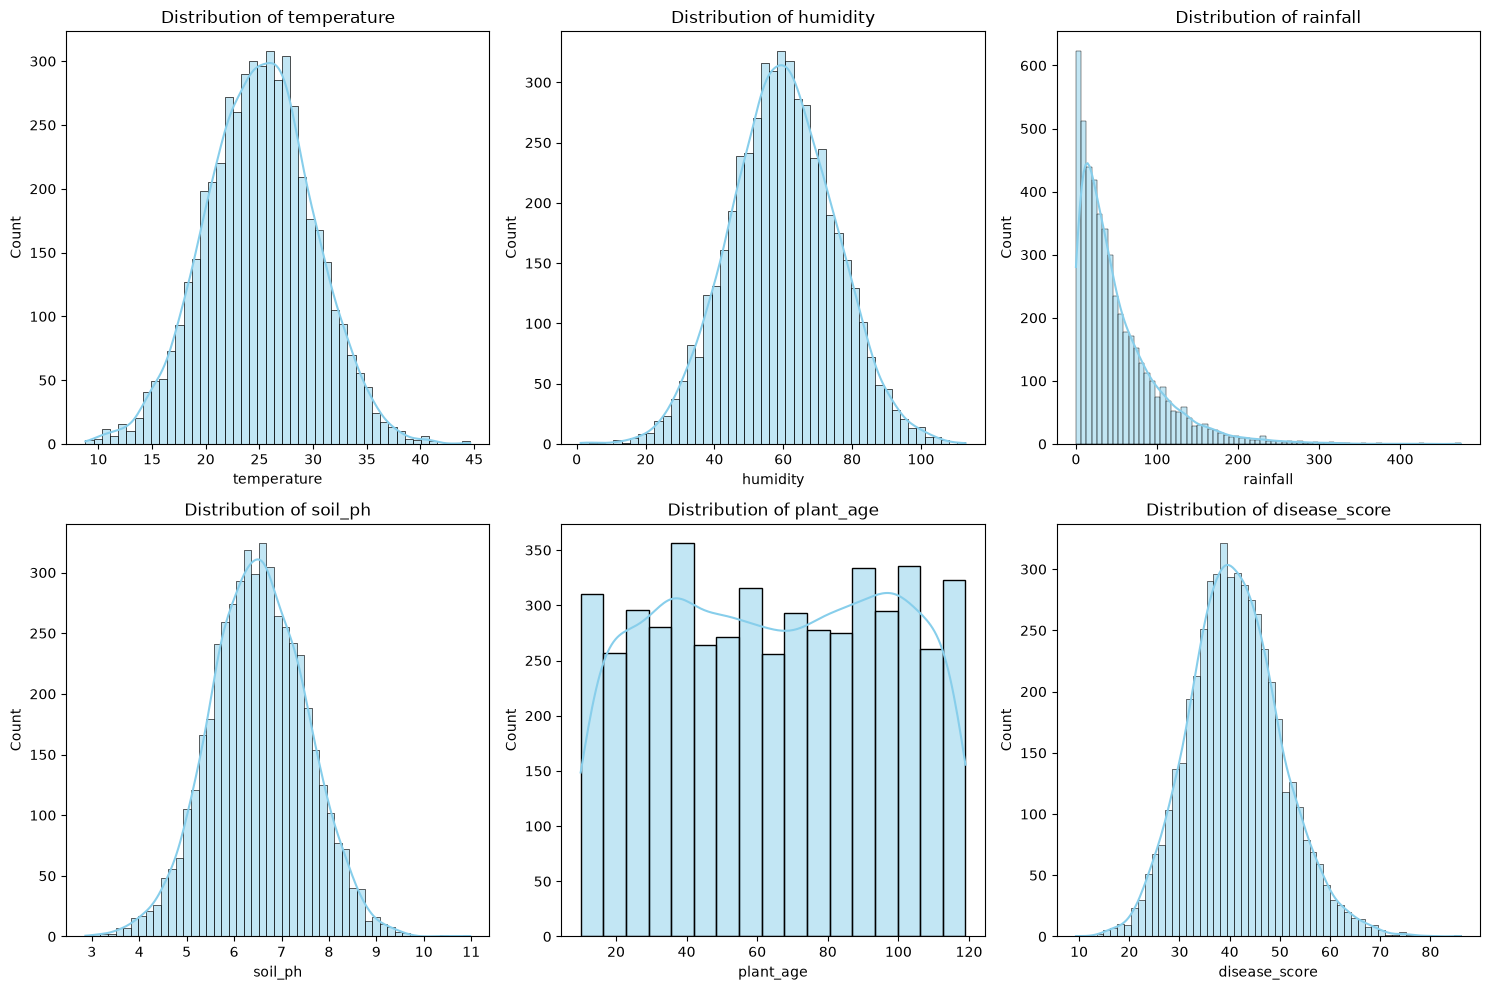


TARGET CLASS BALANCE
target
0    2750
1    2250
Name: count, dtype: int64

Class percentages:
target
0    55.0
1    45.0
Name: proportion, dtype: float64


In [9]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import joblib

# Generate the dataset (as per assignment)
np.random.seed(42)
n = 5000

temperature = np.random.normal(25, 5, n)
humidity = np.random.normal(60, 15, n)
rainfall = np.random.exponential(50, n)
soil_ph = np.random.normal(6.5, 1, n)
plant_age = np.random.randint(10, 120, n)

# Create disease_score (SUSPICIOUS FEATURE)
disease_score = (0.3 * temperature + 0.5 * humidity + 0.1 * rainfall - 0.2 * soil_ph)
target = (disease_score > np.percentile(disease_score, 55)).astype(int)

df = pd.DataFrame({
    'temperature': temperature,
    'humidity': humidity,
    'rainfall': rainfall,
    'soil_ph': soil_ph,
    'plant_age': plant_age,
    'disease_score': disease_score,
    'target': target
})

# SAVE the dataset
df.to_csv('group3_dataset.csv', index=False)

# 1. DATA INSPECTION
print("=" * 50)
print("DATA OVERVIEW")
print("=" * 50)
print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nData Types and Missing Values:")
print(df.info())
print("\nStatistical Summary:")
print(df.describe())

# 2. DISTRIBUTIONS VISUALIZATION
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, col in enumerate(df.columns[:-1]):  # Exclude target
    sns.histplot(df[col], kde=True, ax=axes[idx], color='skyblue')
    axes[idx].set_title(f'Distribution of {col}')
    axes[idx].set_xlabel(col)

plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=300)
plt.show()

# Class balance
print("\n" + "=" * 50)
print("TARGET CLASS BALANCE")
print("=" * 50)
print(df['target'].value_counts())
print("\nClass percentages:")
print(df['target'].value_counts(normalize=True) * 100)